
# 04 - Machine Learning Model Development

## Project: Urban Mobility Demand Intelligence

### Objective
Develop machine learning models to predict hourly bike rental demand using historical data and environmental features.

### Target Variable
- `cnt`: Total number of bike rentals per hour.

### Models to investigate
1. Dummy Regressor (Baseline)
2. Linear Regression
3. Decision Tree Regressor
4. Random Forest Regressor
5. Gradient Boosting Regressor

### Evaluation Metrics
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

In [2]:
# Load the Bike Sharing dataset from the local file already present in the environment
df = pd.read_csv("/Users/sandarunipuna/urban-mobility-demand-intelligence/data/raw/hour.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
X = df.drop(
    columns=["cnt", "casual", "registered", "instant", "dteday"]
)

y = df["cnt"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature shape: (17379, 12)
Target shape: (17379,)

Features:
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


In [4]:
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("Training period:", df["dteday"].iloc[0], "to", df["dteday"].iloc[split_index - 1])
print("Testing period:", df["dteday"].iloc[split_index], "to", df["dteday"].iloc[-1])

Training set: (13903, 12)
Testing set: (3476, 12)
Training period: 2011-01-01 to 2012-08-07
Testing period: 2012-08-07 to 2012-12-31


In [5]:
baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions)
)
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline Model Performance")
print("----------------------")
print(f"MAE:  {baseline_mae:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")
print(f"R²:   {baseline_r2:.4f}")

Baseline Model Performance
----------------------
MAE:  174.98
RMSE: 232.61
R²:   -0.1130


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

/Users/sandarunipuna/urban-mobility-demand-intelligence/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandarunipuna/urban-mobility-demand-intelligence/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/sandarunipuna/urban-mobility-demand-intelligence/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [7]:
print("Feature standard deviations:")
print(X_train.std())

print("\nFeatures with zero variance:")
print(X_train.columns[X_train.std() == 0].tolist())

print("\nFeature correlations:")
print(X_train.corr().round(2))

Feature standard deviations:
season        1.036254
yr            0.484953
mnth          3.218423
hr            6.912235
holiday       0.163264
weekday       2.005710
workingday    0.464749
weathersit    0.644060
temp          0.197716
atemp         0.176614
hum           0.198194
windspeed     0.123023
dtype: float64

Features with zero variance:
[]

Feature correlations:
            season    yr  mnth    hr  holiday  weekday  workingday  \
season        1.00 -0.31  0.86 -0.01    -0.01    -0.00        0.01   
yr           -0.31  1.00 -0.37 -0.01    -0.00    -0.01        0.00   
mnth          0.86 -0.37  1.00 -0.01     0.01     0.01        0.01   
hr           -0.01 -0.01 -0.01  1.00     0.00    -0.00        0.00   
holiday      -0.01 -0.00  0.01  0.00     1.00    -0.10       -0.25   
weekday      -0.00 -0.01  0.01 -0.00    -0.10     1.00        0.03   
workingday    0.01  0.00  0.01  0.00    -0.25     0.03        1.00   
weathersit   -0.02 -0.04 -0.02 -0.03    -0.02     0.02        0.

In [8]:
print("X_train contains NaN:", X_train.isna().any().any())
print("X_train contains infinity:", np.isinf(X_train.select_dtypes(include=np.number)).any().any())

print("X_test contains NaN:", X_test.isna().any().any())
print("X_test contains infinity:", np.isinf(X_test.select_dtypes(include=np.number)).any().any())

print("\nPrediction checks:")
print("NaN predictions:", np.isnan(linear_predictions).any())
print("Infinite predictions:", np.isinf(linear_predictions).any())

print("\nPrediction range:")
print("Minimum:", np.nanmin(linear_predictions))
print("Maximum:", np.nanmax(linear_predictions))

X_train contains NaN: False
X_train contains infinity: False
X_test contains NaN: False
X_test contains infinity: False

Prediction checks:
NaN predictions: False
Infinite predictions: False

Prediction range:
Minimum: -9.902540299817701
Maximum: 432.3285579903471


In [9]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)

In [10]:
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Performance")
print("--------------------")
print(f"MAE:  {rf_mae:.2f}")
print(f"RMSE: {rf_rmse:.2f}")
print(f"R²:   {rf_r2:.4f}")

Random Forest Performance
--------------------
MAE:  45.64
RMSE: 70.28
R²:   0.8984


In [11]:
# Calculate the evaluation metrics for the Linear Regression model first
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

# Create the comparison DataFrame
model_comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression", "Random Forest"],
    "MAE": [baseline_mae, linear_mae, rf_mae],
    "RMSE": [baseline_rmse, linear_rmse, rf_rmse],
    "R2": [baseline_r2, linear_r2, rf_r2]
})

model_comparison = model_comparison.sort_values(by="R2", ascending=False)
model_comparison

,Model,MAE,RMSE,R2
2,Random Forest,45.642427,70.280010,0.898397
1,Linear Regression,138.291753,183.277847,0.309025
0,Baseline,174.984601,232.608375,-0.112995


In [12]:
from sklearn.tree import DecisionTreeRegressor

# Initialize and train Decision Tree Regressor
decision_tree_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

# Predict and evaluate
dt_predictions = decision_tree_model.predict(X_test)

dt_mae = mean_absolute_error(y_test, dt_predictions)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_predictions))
dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Performance")
print("-----------------------")
print(f"MAE:  {dt_mae:.2f}")
print(f"RMSE: {dt_rmse:.2f}")
print(f"R²:   {dt_r2:.4f}")

Decision Tree Performance
-----------------------
MAE:  56.40
RMSE: 88.24
R²:   0.8398


In [13]:
# Rebuild model comparison DataFrame to include Decision Tree
model_comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression", "Decision Tree", "Random Forest"],
    "MAE": [baseline_mae, linear_mae, dt_mae, rf_mae],
    "RMSE": [baseline_rmse, linear_rmse, dt_rmse, rf_rmse],
    "R2": [baseline_r2, linear_r2, dt_r2, rf_r2]
})

model_comparison = model_comparison.sort_values(by="R2", ascending=False)
display(model_comparison)

,Model,MAE,RMSE,R2
3,Random Forest,45.642427,70.280010,0.898397
2,Decision Tree,56.400777,88.236050,0.839847
1,Linear Regression,138.291753,183.277847,0.309025
0,Baseline,174.984601,232.608375,-0.112995


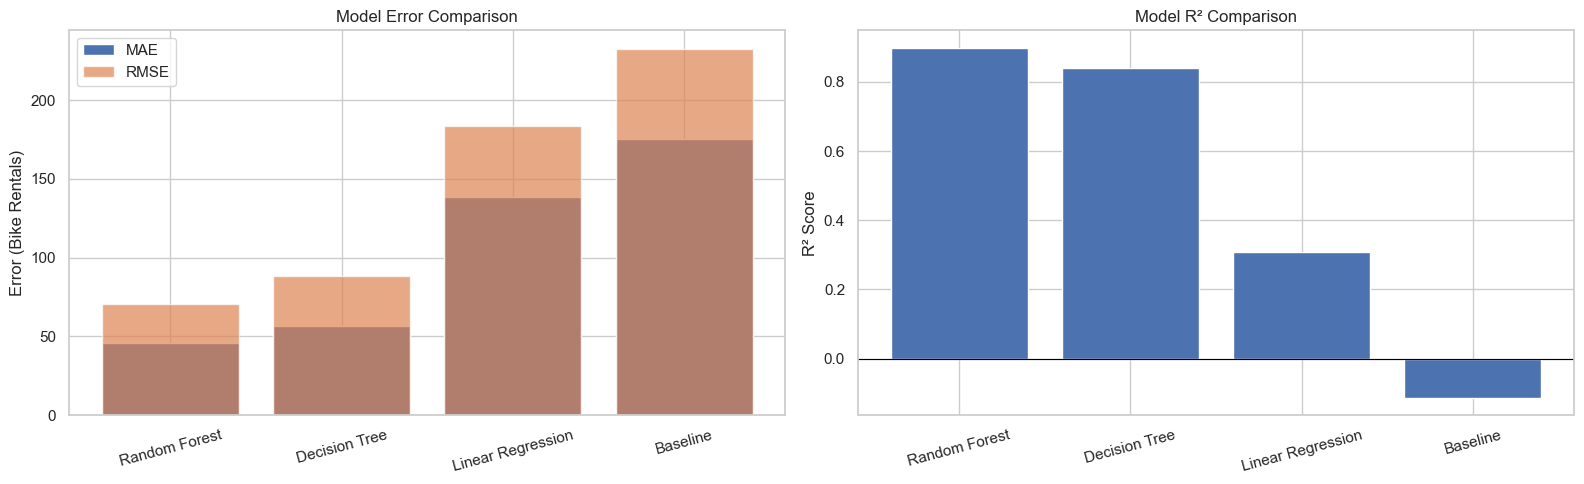

In [14]:
# Re-plot comparisons including Decision Tree
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
model_names = model_comparison["Model"]

# MAE and RMSE Comparison
axes[0].bar(model_names, model_comparison["MAE"], label="MAE")
axes[0].bar(model_names, model_comparison["RMSE"], alpha=0.7, label="RMSE")
axes[0].set_title("Model Error Comparison")
axes[0].set_ylabel("Error (Bike Rentals)")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=15)

# R2 Comparison
axes[1].bar(model_names, model_comparison["R2"])
axes[1].set_title("Model R² Comparison")
axes[1].set_ylabel("R² Score")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

In [15]:
from sklearn.ensemble import GradientBoostingRegressor

# Initialize and train Gradient Boosting Regressor
gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)

gradient_boosting_model.fit(X_train, y_train)

# Predict and evaluate
gb_predictions = gradient_boosting_model.predict(X_test)

gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
gb_r2 = r2_score(y_test, gb_predictions)

print("Gradient Boosting Performance")
print("-----------------------")
print(f"MAE:  {gb_mae:.2f}")
print(f"RMSE: {gb_rmse:.2f}")
print(f"R²:   {gb_r2:.4f}")

Gradient Boosting Performance
-----------------------
MAE:  50.02
RMSE: 76.22
R²:   0.8805


In [16]:
# Rebuild model comparison DataFrame to include Gradient Boosting
model_comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression", "Decision Tree", "Random Forest", "Gradient Boosting"],
    "MAE": [baseline_mae, linear_mae, dt_mae, rf_mae, gb_mae],
    "RMSE": [baseline_rmse, linear_rmse, dt_rmse, rf_rmse, gb_rmse],
    "R2": [baseline_r2, linear_r2, dt_r2, rf_r2, gb_r2]
})

model_comparison = model_comparison.sort_values(by="R2", ascending=False)
display(model_comparison)

,Model,MAE,RMSE,R2
3,Random Forest,45.642427,70.280010,0.898397
4,Gradient Boosting,50.022244,76.215306,0.880511
2,Decision Tree,56.400777,88.236050,0.839847
1,Linear Regression,138.291753,183.277847,0.309025
0,Baseline,174.984601,232.608375,-0.112995


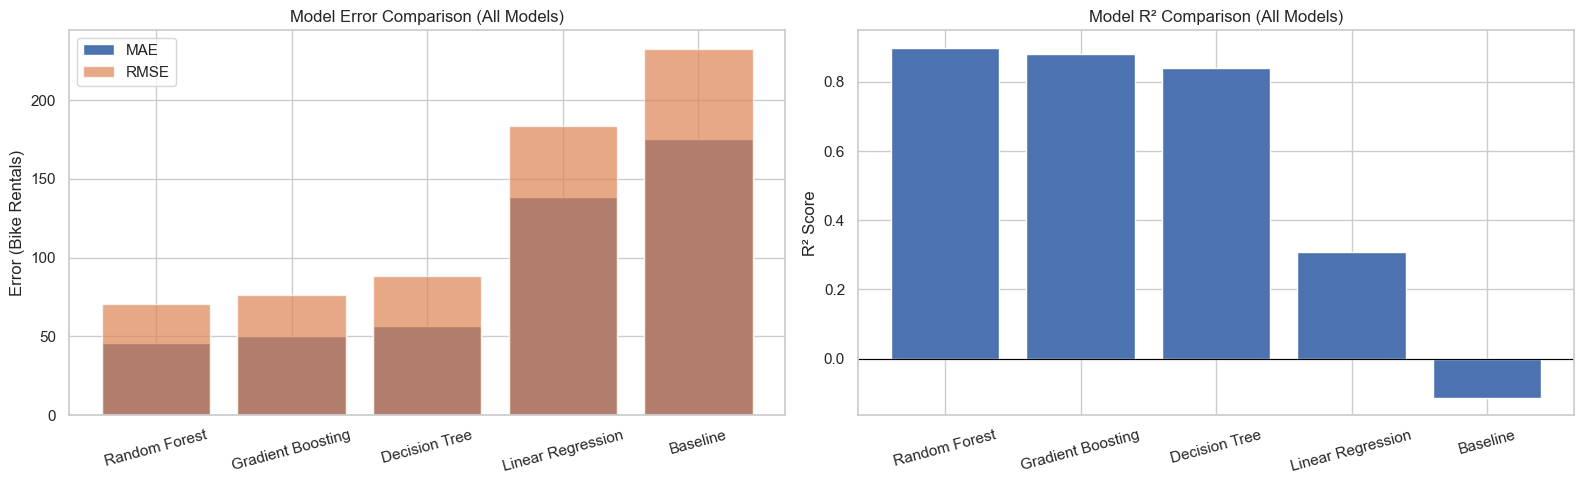

In [17]:
# Re-plot comparisons including Gradient Boosting
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
model_names = model_comparison["Model"]

# MAE and RMSE Comparison
axes[0].bar(model_names, model_comparison["MAE"], label="MAE")
axes[0].bar(model_names, model_comparison["RMSE"], alpha=0.7, label="RMSE")
axes[0].set_title("Model Error Comparison (All Models)")
axes[0].set_ylabel("Error (Bike Rentals)")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=15)

# R2 Comparison
axes[1].bar(model_names, model_comparison["R2"])
axes[1].set_title("Model R² Comparison (All Models)")
axes[1].set_ylabel("R² Score")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

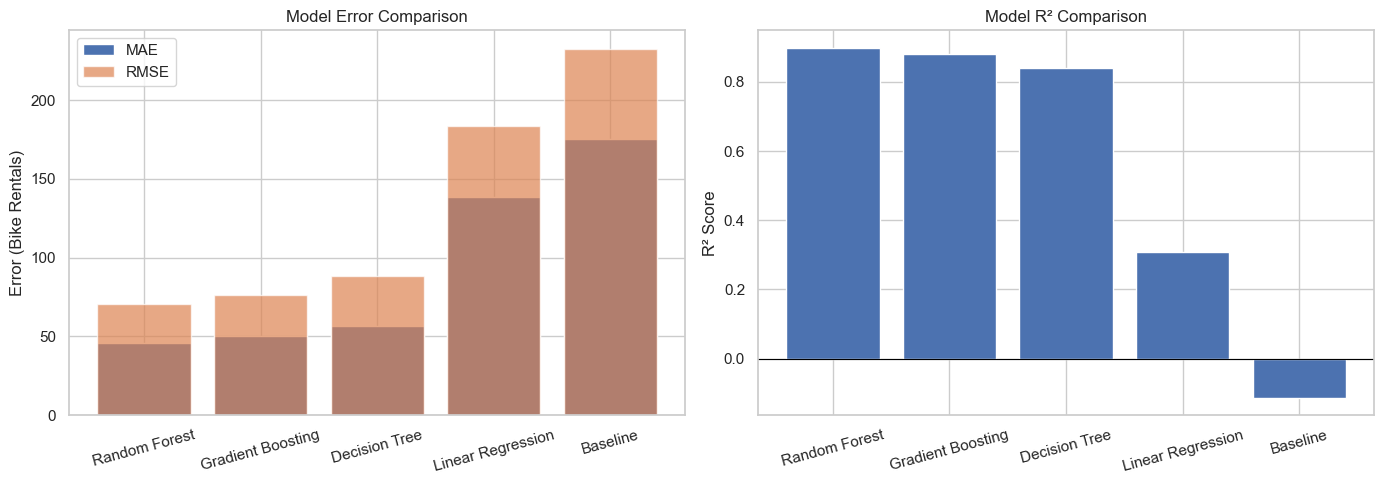

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MAE and RMSE comparison
model_names = model_comparison["Model"]

axes[0].bar(model_names, model_comparison["MAE"], label="MAE")
axes[0].bar(model_names, model_comparison["RMSE"], alpha=0.7, label="RMSE")

axes[0].set_title("Model Error Comparison")
axes[0].set_ylabel("Error (Bike Rentals)")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=15)

# R2 comparison
axes[1].bar(model_names, model_comparison["R2"])
axes[1].set_title("Model R² Comparison")
axes[1].set_ylabel("R² Score")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

In [19]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

feature_importance

,Feature,Importance
3,hr,0.616614
9,atemp,0.094064
8,temp,0.072227
1,yr,0.069943
6,workingday,0.058384
10,hum,0.024503
7,weathersit,0.018335
0,season,0.012993
2,mnth,0.011931
5,weekday,0.011558


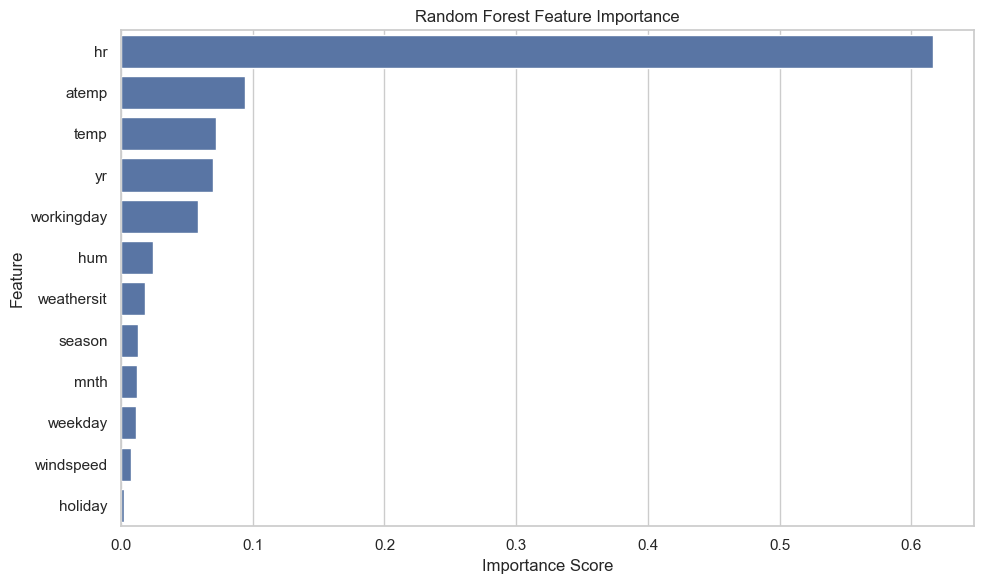

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

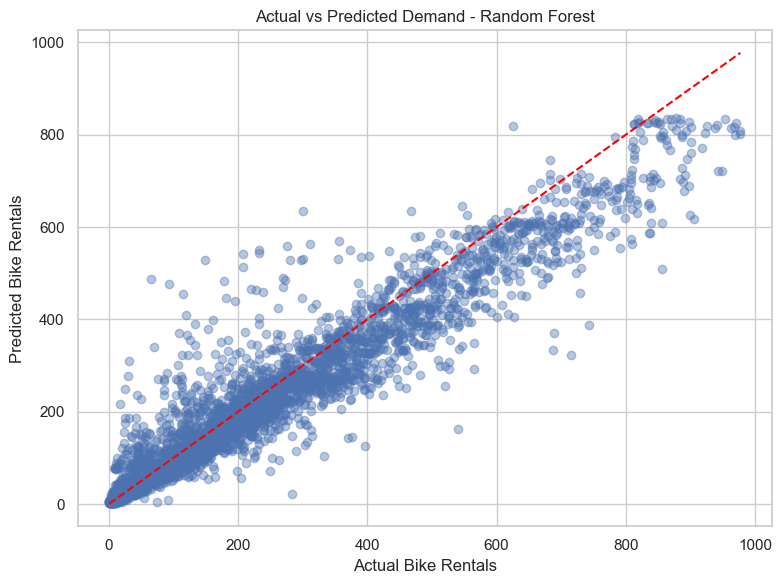

In [21]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_predictions, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")
plt.title("Actual vs Predicted Demand - Random Forest")

plt.tight_layout()
plt.show()

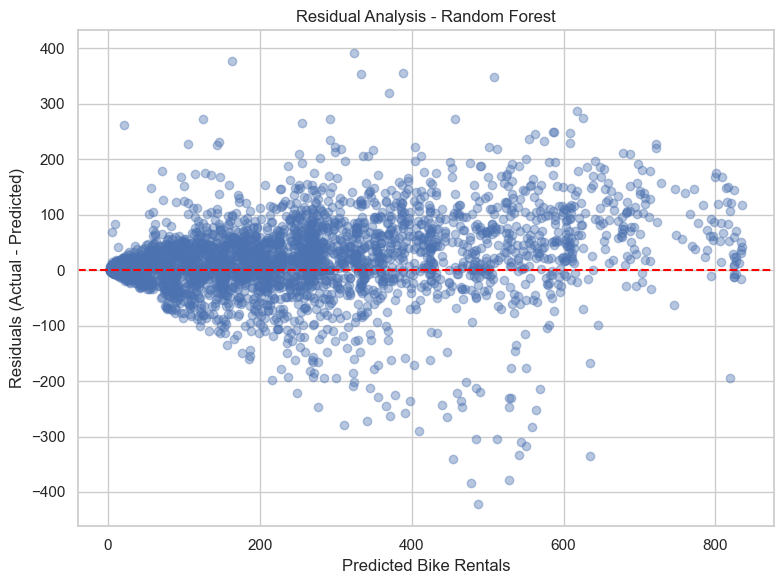

In [22]:
residuals = y_test - rf_predictions

plt.figure(figsize=(8, 6))

plt.scatter(rf_predictions, residuals, alpha=0.4)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Bike Rentals")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Analysis - Random Forest")

plt.tight_layout()
plt.show()

In [23]:
from sklearn.model_selection import GridSearchCV

# Set up parameter grid for tuning
param_grid = {
    'n_estimators': [100, 150],
    'max_depth': [15, 20],
    'min_samples_split': [2, 5]
}

# Initialize Grid Search with 3-fold cross validation for speed
rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

print("Starting Hyperparameter Tuning for Random Forest...")
rf_grid.fit(X_train, y_train)

best_rf_model = rf_grid.best_estimator_
print("Best Parameters Found:", rf_grid.best_params_)

Starting Hyperparameter Tuning for Random Forest...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters Found: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 100}


In [24]:
# Evaluate the tuned Random Forest model
tuned_rf_predictions = best_rf_model.predict(X_test)

tuned_rf_mae = mean_absolute_error(y_test, tuned_rf_predictions)
tuned_rf_rmse = np.sqrt(mean_squared_error(y_test, tuned_rf_predictions))
tuned_rf_r2 = r2_score(y_test, tuned_rf_predictions)

print("Tuned Random Forest Performance")
print("-----------------------")
print(f"MAE:  {tuned_rf_mae:.2f}  (Previous: {rf_mae:.2f})")
print(f"RMSE: {tuned_rf_rmse:.2f}  (Previous: {rf_rmse:.2f})")
print(f"R²:   {tuned_rf_r2:.4f}  (Previous: {rf_r2:.4f})")

Tuned Random Forest Performance
-----------------------
MAE:  45.09  (Previous: 45.64)
RMSE: 69.69  (Previous: 70.28)
R²:   0.9001  (Previous: 0.8984)


In [25]:
# Calculate feature importances for the tuned Random Forest model
tuned_feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_rf_model.feature_importances_
})

tuned_feature_importance = tuned_feature_importance.sort_values(
    by="Importance", ascending=False
)

display(tuned_feature_importance)

,Feature,Importance
3,hr,0.610832
9,atemp,0.088184
8,temp,0.078700
1,yr,0.069202
6,workingday,0.057779
10,hum,0.026404
7,weathersit,0.018897
0,season,0.013145
2,mnth,0.013088
5,weekday,0.012071


/var/folders/z8/d_2qx_z91vbbpc4stlbd25t40000gn/T/ipykernel_29121/2587267083.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


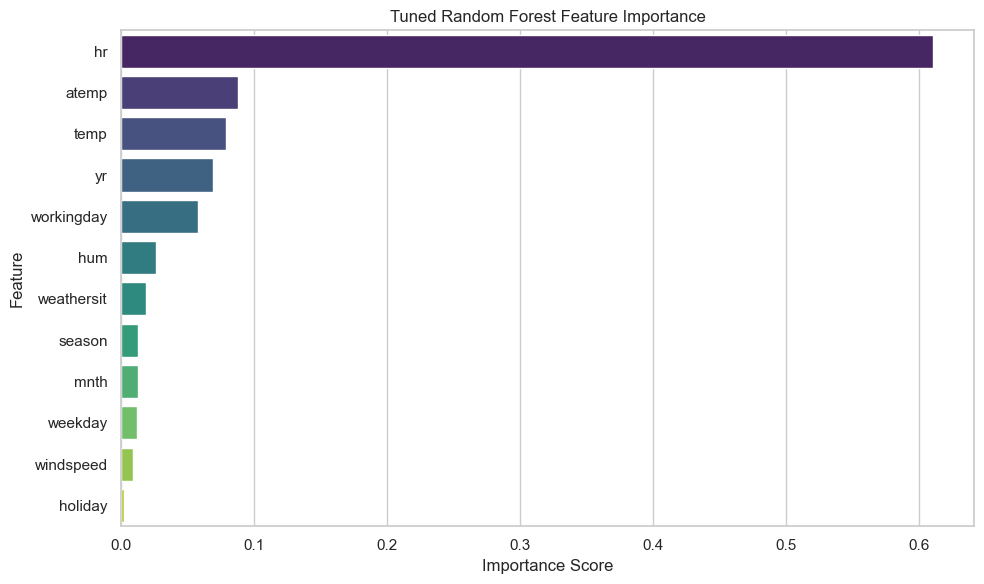

In [26]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=tuned_feature_importance,
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title("Tuned Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

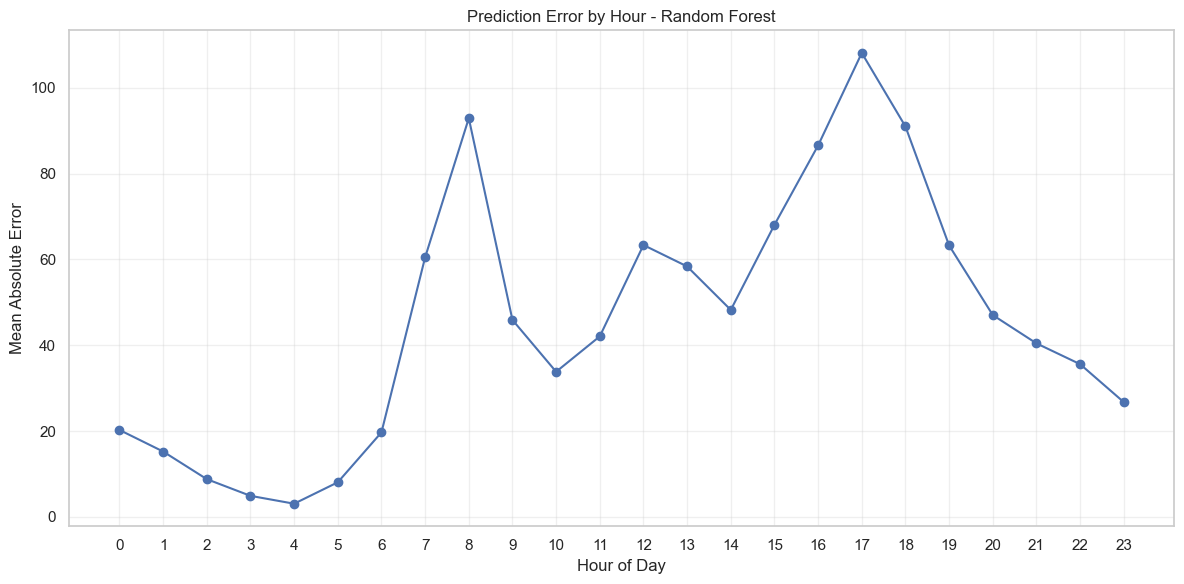

In [27]:
hourly_results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": rf_predictions,
    "Hour": X_test["hr"]
})

hourly_results["Absolute_Error"] = abs(
    hourly_results["Actual"] - hourly_results["Predicted"]
)

hourly_mae = hourly_results.groupby("Hour")["Absolute_Error"].mean()

plt.figure(figsize=(12, 6))

plt.plot(hourly_mae.index, hourly_mae.values, marker="o")

plt.xlabel("Hour of Day")
plt.ylabel("Mean Absolute Error")
plt.title("Prediction Error by Hour - Random Forest")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Saving the Tuned Random Forest Model
We will use `joblib` to export the trained model to a file. This file can be downloaded and used to serve predictions in production environments.

In [31]:
import joblib

model_path = 'best_random_forest_model.joblib'

joblib.dump(best_rf_model, model_path)

print(f"Successfully saved the tuned Random Forest model to: {model_path}")

Successfully saved the tuned Random Forest model to: best_random_forest_model.joblib
